In [31]:
import numpy as np
from matplotlib.pyplot import *
cr = rcParams['axes.prop_cycle'].by_key()['color']

In [389]:
mass = np.logspace(-34,-28,20)
mass_id = [14]
n = 145
alpha0 = 0.34 # [deg]
Tcmb = 2.7255e6

In [390]:
cls = np.loadtxt('../../data_local/cosmo2017_10K_acc3_lensedCls.dat',unpack=True)

In [391]:
Ucl = {mi: np.loadtxt('./output/data0/alpha0.34deg_'+str(n)+'maki_p0_'+str(mass[mi])+'_N10000+cl.dat',unpack=True) for mi in mass_id}
Lcl = {mi: np.loadtxt('./output/data0/alpha0.34deg_'+str(n)+'maki_p0_'+str(mass[mi])+'_N10000+cl_lensed.dat',unpack=True) for mi in mass_id}
ucl = {mi: np.loadtxt('./output/alpha0.34deg_'+str(n)+'maki_p0_'+str(mass[mi])+'_N10000+cl.dat',unpack=True) for mi in mass_id}
lcl = {mi: np.loadtxt('./output/alpha0.34deg_'+str(n)+'maki_p0_'+str(mass[mi])+'_N10000+cl_lensed.dat',unpack=True) for mi in mass_id}

In [392]:
for mi in mass_id:
    print(mass[mi]) 

2.6366508987303447e-30


In [393]:
l = ucl[mass_id[0]][0]
L = lcl[mass_id[0]][0]
UEE = {mi: Ucl[mi][2] for mi in mass_id}
UEB = {mi: Ucl[mi][5] for mi in mass_id}
uEE = {mi: ucl[mi][2] for mi in mass_id}
uEB = {mi: ucl[mi][5] for mi in mass_id}
lEE = {mi: lcl[mi][2] for mi in mass_id}
lEB = {mi: lcl[mi][5] for mi in mass_id}

In [394]:
print(UEE[mass_id[0]]/uEE[mass_id[0]])

[0.95056218 0.96864255 0.96872254 ... 0.99999892 0.99999891 0.99999891]


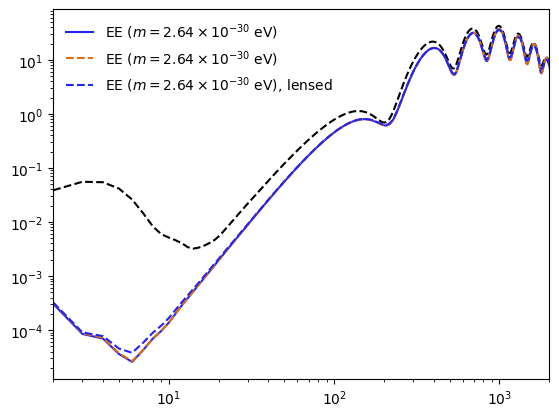

In [395]:
xscale('log')
yscale('log')
xlim(2,2000)
plot(cls[0],cls[2],color='k',ls='--')
for i, mi in enumerate(mass_id):
    label = r'EE ($m='+'{:.2E}'.format(mass[mi]).replace("E", r"\times 10^{").replace("+", "")+'}$ eV)'
    plot(l,UEE[mi]*Tcmb**2,label=label,color=cr[i])
    plot(l,uEE[mi]*Tcmb**2,label=label,color=cr[i+1],ls='--')
    plot(L,lEE[mi]*Tcmb**2,label=label+', lensed',color=cr[i],ls='--')
legend()

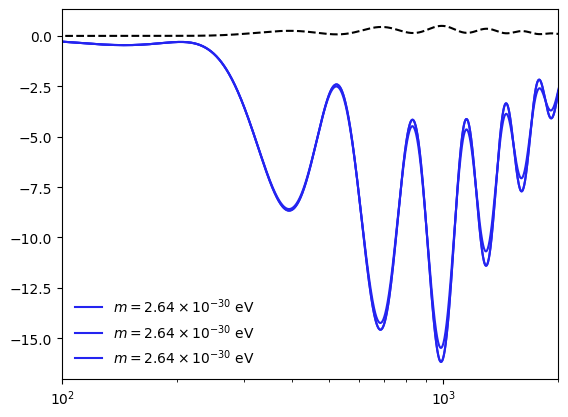

In [396]:
xscale('log')
xlim(100,2000)
plot(cls[0],(np.sin(4*0.34*np.pi/180.)/2)*cls[2],color='k',ls='--')
for i, mi in enumerate(mass_id):
    label = r'$m='+'{:.2E}'.format(mass[mi]).replace("E", r"\times 10^{").replace("+", "")+'}$ eV'
    plot(l,UEB[mi]*Tcmb**2,label=label,color=cr[i])
    plot(l,uEB[mi]*Tcmb**2,label=label,color=cr[i])
    plot(L,lEB[mi]*Tcmb**2,label=label,color=cr[i])
legend()

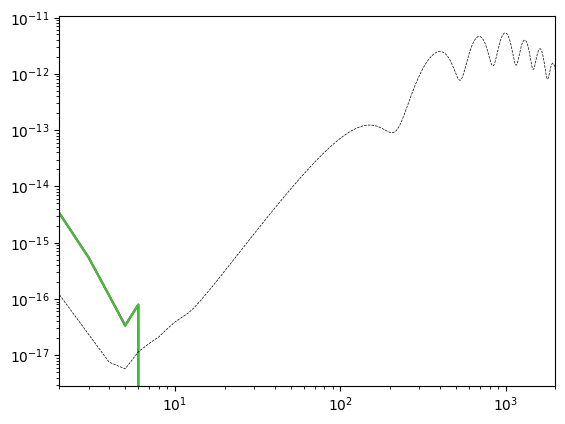

In [388]:
yscale('log')
xscale('log')
xlim(min(L),max(L))
mid = mass_id[0]
plot(l,UEB[mid]/(2*.34*np.pi/180.))
plot(l,uEB[mid]/(2*.34*np.pi/180.))
plot(L,lEB[mid]/(2*.34*np.pi/180.))
plot(l,uEE[mid],ls='--',color='k',lw=.5)